# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: LogisticRegression
Test: (36, 13)


## 2. Evaluación final

Accuracy CV (train) : 0.9791 ± 0.0277
Accuracy test       : 0.9722
F1 macro test       : 0.9710

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        12
           1      0.933     1.000     0.966        14
           2      1.000     0.900     0.947        10

    accuracy                          0.972        36
   macro avg      0.978     0.967     0.971        36
weighted avg      0.974     0.972     0.972        36



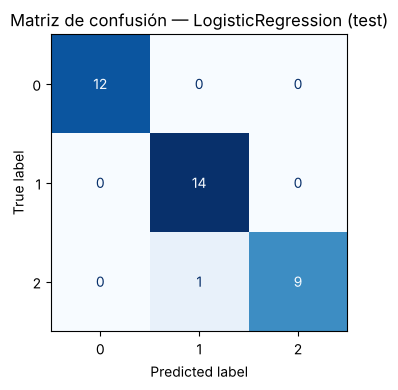

Errores en test:
   target  prediccion
1       2           1


In [4]:
y_pred = model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy CV (train) : {training_metadata['cv_accuracy_mean']:.4f} ± {training_metadata['cv_accuracy_std']:.4f}")
print(f"Accuracy test       : {test_accuracy:.4f}")
print(f"F1 macro test       : {test_f1_macro:.4f}")
print()
print(classification_report(y_test, y_pred, digits=3))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusión — {training_metadata['champion']} (test)")
plt.tight_layout()
plt.show()

errores = test_df.loc[y_pred != y_test, [contract["target"]]].assign(prediccion=y_pred[y_pred != y_test])
print("Errores en test:")
print(errores if len(errores) else "ninguno")


**Análisis:**

> - **Coherencia con CV:** sí. La accuracy en test (**0.972**) cae dentro del rango esperado por validación cruzada (**0.979 ± 0.028**). La diferencia de 0.7 puntos equivale a la mitad de un ejemplo de 36 y está muy por debajo de una desviación estándar. El F1 macro (**0.971**) es casi igual a la accuracy, así que el desempeño es parejo entre clases pese al leve desbalance.
> - **Clases que se confunden:** solo hay **un error**: un vino de la **clase 2** clasificado como **clase 1**. Eso explica el recall de 0.90 en la clase 2 y la precisión de 0.933 en la clase 1. La clase 0 se clasifica perfectamente. Es coherente con el EDA: la clase 0 se separa claramente por su `proline` alto, mientras que las clases 1 y 2 comparten rangos en varias variables. En el lote de inferencia (registro 1) se ve un caso así: el modelo duda entre la clase 1 (0.54) y la clase 2 (0.45).
> - **Sobreajuste:** no hay evidencia relevante. Aunque la accuracy de entrenamiento fue 1.00, el modelo **generaliza a datos nunca vistos** casi igual que en CV. Como el test se abrió una sola vez y no se reajustó nada después, la estimación no está sesgada. Con solo 36 muestras de test, cada error mueve la accuracy unos 2.8 puntos, así que la estimación tiene una incertidumbre considerable.


## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    if not isinstance(records, pd.DataFrame):
        raise TypeError("records debe ser un pandas.DataFrame")

    # Columnas faltantes -> error explícito
    missing = [c for c in feature_columns if c not in records.columns]
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")

    # Columnas extra se ignoran; se ordenan como en entrenamiento
    X = records[feature_columns].apply(pd.to_numeric, errors="raise")

    predictions = model.predict(X)
    probabilities = model.predict_proba(X)

    result = pd.DataFrame(index=records.index)
    result["prediction"] = predictions
    for cls, col in zip(model.classes_, probabilities.T):
        result[f"proba_class_{cls}"] = col
    return result


# Prueba rápida de la validación de esquema
try:
    predict(X_test.drop(columns=["proline"]).iloc[:1])
except ValueError as e:
    print("Validación OK ->", e)


Validación OK -> Faltan columnas requeridas: ['proline']


## 4. Predicción por lotes

In [6]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

# Columnas desordenadas para comprobar que predict reordena correctamente
new_records = new_records[new_records.columns[::-1]]

batch_predictions = predict(new_records)
batch_output = pd.concat([new_records[feature_columns], batch_predictions], axis=1)
batch_output.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)

batch_predictions.round(4)


,prediction,proba_class_0,proba_class_1,proba_class_2
0,0,0.9997,0.0003,0.0000
1,1,0.0071,0.5404,0.4525
2,0,0.9920,0.0077,0.0003
3,1,0.2900,0.7075,0.0026
4,1,0.0330,0.9623,0.0047


## 5. Reporte final

In [7]:
test_metrics = {
    "model": training_metadata["champion"],
    "best_params": training_metadata["best_params"],
    "cv_accuracy_mean": training_metadata["cv_accuracy_mean"],
    "test_accuracy": float(test_accuracy),
    "test_f1_macro": float(test_f1_macro),
    "n_test": int(len(X_test)),
}
(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(json.dumps(test_metrics, indent=2, ensure_ascii=False))


{
  "model": "LogisticRegression",
  "best_params": {
    "model__C": 1.0
  },
  "cv_accuracy_mean": 0.9790640394088669,
  "test_accuracy": 0.9722222222222222,
  "test_f1_macro": 0.9709618874773139,
  "n_test": 36
}


In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | Regresión Logística (`C = 1.0`) con imputación por mediana + `StandardScaler` dentro del pipeline |
| Accuracy CV | 0.979 ± 0.028 (5 folds estratificados, solo train) |
| Accuracy test | 0.972 (35 de 36 correctos) |
| F1 macro test | 0.971 |
| Clases más confundidas | Clase 2 → clase 1 (1 caso). La clase 0 no tiene errores. |
| Principal limitación | Dataset muy pequeño (178 vinos, 36 en test): cada error mueve la métrica ≈ 2.8 pts y el modelo solo se ha validado con vinos de los mismos 3 cultivares y la misma fuente. Datos de otra región o laboratorio podrían cambiar las distribuciones (data drift). |

## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.
